
# 05 — Modelos Baseline

## Taller de Análisis de Datos I — TP3

### Objetivo

Construir y evaluar modelos sencillos de corrección
del error de temperatura para pronósticos meteorológicos
de 12 y 24 horas.

Los modelos baseline permiten establecer referencias
de desempeño antes de aplicar técnicas de Machine Learning
más complejas.

### Metodología

Se utilizan los datos históricos del 10 de septiembre
al 1 de noviembre de 2026, excluyendo los cinco días
anómalos identificados durante la auditoría.

La partición es cronológica:

- Entrenamiento: 10/09 al 17/10.
- Validación: 18/10 al 01/11.
- Exclusión por calidad: 22/10 al 26/10.
- Prueba final reservada: 02/11 al 09/11.

Se aplica una purga temporal para evitar entrenar
con observaciones que todavía no estaban disponibles
al emitirse los primeros pronósticos de validación.

Los modelos se ajustarán exclusivamente sobre el
conjunto de entrenamiento seguro.


In [1]:

# ==========================================
# 05 - CELDA 1
# CARGA HISTÓRICA Y PARTICIÓN TEMPORAL
# ==========================================

from pathlib import Path
import numpy as np
import pandas as pd

# ------------------------------------------
# 1. LOCALIZAR DATASET
# ------------------------------------------

raiz_proyecto = Path.cwd().parent
carpeta_dataset = raiz_proyecto / "dataset"

assert carpeta_dataset.is_dir(), (
    f"No existe la carpeta: {carpeta_dataset}"
)

# ------------------------------------------
# 2. SELECCIONAR FECHAS HISTÓRICAS
# ------------------------------------------

fechas_historicas = pd.date_range(
    "2026-09-10",
    "2026-11-01",
    freq="D"
)

fechas_excluidas = set(
    pd.date_range(
        "2026-10-22",
        "2026-10-26",
        freq="D"
    ).date
)

archivos_historicos = [
    carpeta_dataset / (
        "forecast_observation_"
        + fecha.strftime("%Y_%m_%d")
        + ".csv"
    )
    for fecha in fechas_historicas
    if fecha.date() not in fechas_excluidas
]

assert len(archivos_historicos) == 48
assert all(
    archivo.is_file()
    for archivo in archivos_historicos
)

print("ARCHIVOS HISTÓRICOS:")
print(len(archivos_historicos))

# ------------------------------------------
# 3. CARGAR COLUMNAS NECESARIAS
# ------------------------------------------

columnas = [
    "station_id",
    "target_time_utc",
    "collection_time_utc",
    "forecast_generated_at_utc",
    "observation_collection_hour_utc",
    "horizon_target_hours",
    "match_type",
    "temperature_forecast_c",
    "temperature_observed_c"
]

fragmentos = []

for archivo in archivos_historicos:

    bloque = pd.read_csv(
        archivo,
        usecols=columnas
    )

    for columna in [
        "horizon_target_hours",
        "temperature_forecast_c",
        "temperature_observed_c"
    ]:
        bloque[columna] = pd.to_numeric(
            bloque[columna],
            errors="coerce"
        )

    filtro = (
        bloque["horizon_target_hours"].isin([12, 24])
        & bloque["match_type"].eq("interval")
        & np.isfinite(
            bloque["temperature_forecast_c"]
        )
        & np.isfinite(
            bloque["temperature_observed_c"]
        )
    )

    fragmentos.append(
        bloque.loc[filtro].copy()
    )

df_baseline = pd.concat(
    fragmentos,
    ignore_index=True
)

del fragmentos

# ------------------------------------------
# 4. CONVERTIR FECHAS
# ------------------------------------------

columnas_fecha = [
    "target_time_utc",
    "collection_time_utc",
    "forecast_generated_at_utc",
    "observation_collection_hour_utc"
]

for columna in columnas_fecha:
    df_baseline[columna] = pd.to_datetime(
        df_baseline[columna],
        utc=True,
        errors="coerce"
    )

assert df_baseline[columnas_fecha].notna().all().all()

# ------------------------------------------
# 5. DEFINIR VARIABLE OBJETIVO
# ------------------------------------------

df_baseline["error_c"] = (
    df_baseline["temperature_observed_c"]
    - df_baseline["temperature_forecast_c"]
)

# ------------------------------------------
# 6. SEPARACIÓN CRONOLÓGICA
# ------------------------------------------

inicio_validacion = pd.Timestamp(
    "2026-10-18",
    tz="UTC"
)

df_train_original = df_baseline.loc[
    df_baseline["target_time_utc"]
    < inicio_validacion
].copy()

df_val_baseline = df_baseline.loc[
    df_baseline["target_time_utc"]
    >= inicio_validacion
].copy()

# ------------------------------------------
# 7. REPRODUCIR PURGA TEMPORAL DEL NOTEBOOK 04
# ------------------------------------------

# Primera emisión efectiva de validación
emision_validacion = df_val_baseline[
    [
        "collection_time_utc",
        "forecast_generated_at_utc"
    ]
].max(axis=1)

primera_emision_validacion = (
    emision_validacion.min()
)

# Disponibilidad estimada de cada
# etiqueta de entrenamiento
emision_train = df_train_original[
    [
        "collection_time_utc",
        "forecast_generated_at_utc"
    ]
].max(axis=1)

observacion_disponible = (
    df_train_original[
        "observation_collection_hour_utc"
    ]
    + pd.Timedelta(hours=2)
)

disponibilidad_error = pd.concat(
    [
        emision_train.rename("emision"),
        observacion_disponible.rename("observacion")
    ],
    axis=1
).max(axis=1)

mascara_segura = (
    disponibilidad_error
    < primera_emision_validacion
)

df_train_baseline = df_train_original.loc[
    mascara_segura
].copy()

# ------------------------------------------
# 8. AUDITORÍA
# ------------------------------------------

print("\nPARTICIÓN HISTÓRICA:")

resumen = pd.DataFrame({
    "conjunto": [
        "Histórico completo",
        "Entrenamiento original",
        "Entrenamiento seguro",
        "Validación"
    ],
    "registros": [
        len(df_baseline),
        len(df_train_original),
        len(df_train_baseline),
        len(df_val_baseline)
    ]
})

display(resumen)

print("\nPRIMERA EMISIÓN DE VALIDACIÓN:")
print(primera_emision_validacion)

print("\nREGISTROS POR HORIZONTE:")

display(
    pd.DataFrame({
        "train": (
            df_train_baseline[
                "horizon_target_hours"
            ].value_counts()
        ),
        "validacion": (
            df_val_baseline[
                "horizon_target_hours"
            ].value_counts()
        )
    }).sort_index()
)

# ------------------------------------------
# 9. CONTROLES FINALES
# ------------------------------------------

assert len(df_baseline) == 854009
assert len(df_train_original) == 680426
assert len(df_train_baseline) == 659992
assert len(df_val_baseline) == 173583

assert (
    disponibilidad_error.loc[mascara_segura]
    < primera_emision_validacion
).all()

assert np.isfinite(
    df_train_baseline["error_c"]
).all()

assert np.isfinite(
    df_val_baseline["error_c"]
).all()

print("\nCONTROL FINAL:")
print("Datos históricos preparados correctamente.")
print("Purga temporal reproducida.")
print("Noviembre 02-09 no fue utilizado.")


ARCHIVOS HISTÓRICOS:
48

PARTICIÓN HISTÓRICA:


,conjunto,registros
0,Histórico completo,854009
1,Entrenamiento original,680426
2,Entrenamiento seguro,659992
3,Validación,173583



PRIMERA EMISIÓN DE VALIDACIÓN:
2026-10-17 00:15:05.855401+00:00

REGISTROS POR HORIZONTE:


,train,validacion
horizon_target_hours,,
12,330000,86792
24,329992,86791



CONTROL FINAL:
Datos históricos preparados correctamente.
Purga temporal reproducida.
Noviembre 02-09 no fue utilizado.


In [2]:

# ==========================================
# 05 - CELDA 2
# BASELINES B0 Y B1
# ==========================================

import numpy as np
import pandas as pd

# ------------------------------------------
# 1. VARIABLE OBJETIVO
# ------------------------------------------

# Error = observado - pronosticado
error_train = df_train_baseline[
    "error_c"
].to_numpy(dtype=float)

error_val = df_val_baseline[
    "error_c"
].to_numpy(dtype=float)

horizontes_val = df_val_baseline[
    "horizon_target_hours"
].to_numpy()

assert np.isfinite(error_train).all()
assert np.isfinite(error_val).all()

# ------------------------------------------
# 2. BASELINE B0 - SIN CORRECCIÓN
# ------------------------------------------

# El error estimado es siempre cero.
correccion_b0 = np.zeros(
    len(df_val_baseline)
)

# ------------------------------------------
# 3. BASELINE B1 - SESGO GLOBAL
# ------------------------------------------

# Aprendemos una única corrección
# utilizando exclusivamente entrenamiento.

sesgo_global_train = error_train.mean()

correccion_b1 = np.full(
    len(df_val_baseline),
    sesgo_global_train
)

print("SESGO GLOBAL APRENDIDO:")
print(
    f"{sesgo_global_train:+.4f} °C"
)

# ------------------------------------------
# 4. FUNCIÓN DE EVALUACIÓN
# ------------------------------------------

def evaluar_baseline(
    nombre,
    error_real,
    correccion,
    horizonte
):

    residual = error_real - correccion

    mae = np.mean(np.abs(residual))

    rmse = np.sqrt(
        np.mean(residual ** 2)
    )

    sesgo = np.mean(residual)

    return {
        "horizonte_h": horizonte,
        "modelo": nombre,
        "registros": len(error_real),
        "MAE_c": mae,
        "RMSE_c": rmse,
        "sesgo_c": sesgo
    }

# ------------------------------------------
# 5. COMPARACIÓN POR HORIZONTE
# ------------------------------------------

resultados = []

for horizonte in [12, 24]:

    mascara = horizontes_val == horizonte

    real = error_val[mascara]

    for nombre, correccion in [
        ("B0 - Original", correccion_b0),
        ("B1 - Sesgo global", correccion_b1)
    ]:

        resultados.append(
            evaluar_baseline(
                nombre=nombre,
                error_real=real,
                correccion=correccion[mascara],
                horizonte=horizonte
            )
        )

df_baselines_01 = pd.DataFrame(
    resultados
)

# ------------------------------------------
# 6. CALCULAR MEJORA CONTRA B0
# ------------------------------------------

mae_original_por_horizonte = (
    df_baselines_01.loc[
        df_baselines_01["modelo"]
        == "B0 - Original"
    ]
    .set_index("horizonte_h")["MAE_c"]
)

df_baselines_01["mejora_MAE_pct"] = (
    100 * (
        1
        - df_baselines_01["MAE_c"]
        / df_baselines_01["horizonte_h"].map(
            mae_original_por_horizonte
        )
    )
)

print("\nCOMPARACIÓN POR HORIZONTE:")

display(
    df_baselines_01.round(4)
)

# ------------------------------------------
# 7. COMPARACIÓN GLOBAL
# ------------------------------------------

resultados_globales = []

for nombre, correccion in [
    ("B0 - Original", correccion_b0),
    ("B1 - Sesgo global", correccion_b1)
]:

    resultados_globales.append(
        evaluar_baseline(
            nombre=nombre,
            error_real=error_val,
            correccion=correccion,
            horizonte="Global"
        )
    )

df_baselines_global = pd.DataFrame(
    resultados_globales
)

mae_global_b0 = df_baselines_global.loc[
    df_baselines_global["modelo"]
    == "B0 - Original",
    "MAE_c"
].iloc[0]

df_baselines_global["mejora_MAE_pct"] = (
    100 * (
        1
        - df_baselines_global["MAE_c"]
        / mae_global_b0
    )
)

print("\nCOMPARACIÓN GLOBAL:")

display(
    df_baselines_global.round(4)
)

# ------------------------------------------
# 8. VERIFICACIONES FINALES
# ------------------------------------------

assert len(df_baselines_01) == 4
assert len(df_baselines_global) == 2

assert len(error_train) == 659992
assert len(error_val) == 173583

assert np.isfinite(correccion_b1).all()

assert (
    df_baselines_01["registros"].sum()
    == 2 * len(df_val_baseline)
)

print("\nCONTROL FINAL:")
print("B0: pronóstico original evaluado.")
print("B1: sesgo aprendido solo con entrenamiento.")
print("Validación histórica utilizada correctamente.")
print("Noviembre 02-09 no fue utilizado.")


SESGO GLOBAL APRENDIDO:
+0.0293 °C

COMPARACIÓN POR HORIZONTE:


,horizonte_h,modelo,registros,MAE_c,RMSE_c,sesgo_c,mejora_MAE_pct
0,12,B0 - Original,86792,1.5636,1.9753,0.1572,0.0000
1,12,B1 - Sesgo global,86792,1.5620,1.9732,0.1279,0.1006
2,24,B0 - Original,86791,1.5646,1.9686,0.1568,0.0000
3,24,B1 - Sesgo global,86791,1.5629,1.9665,0.1275,0.1078



COMPARACIÓN GLOBAL:


,horizonte_h,modelo,registros,MAE_c,RMSE_c,sesgo_c,mejora_MAE_pct
0,Global,B0 - Original,173583,1.5641,1.9719,0.1570,0.0000
1,Global,B1 - Sesgo global,173583,1.5625,1.9698,0.1277,0.1042



CONTROL FINAL:
B0: pronóstico original evaluado.
B1: sesgo aprendido solo con entrenamiento.
Validación histórica utilizada correctamente.
Noviembre 02-09 no fue utilizado.


#### ¿Qué vamos a analizar?

La salida tendrá tres partes:
1. Sesgo global aprendido: cuánto corrige B1 cada pronóstico.
2. Comparación por horizonte: cómo funciona B1 a 12 y 24 horas.
3. Comparación global: si corregir solamente el sesgo histórico consigue reducir el MAE.
Es posible que B1 reduzca el sesgo medio pero no mejore el MAE. Ambos indicadores miden cosas diferentes, y esa distinción será útil para justificar por qué necesitamos modelos más complejos.

B0 — Pronóstico sin corrección

Es el pronóstico meteorológico original. No aprende nada ni modifica temperaturas.

B1 — Corrección por sesgo global

Calcula cuánto se equivocaron, en promedio, los pronósticos del conjunto de entrenamiento.

Por ejemplo, si históricamente las observaciones fueran 0,3 °C superiores a los pronósticos, el baseline sumaría 0,3 °C a cada predicción.

La fórmula es:
\[
$\widehat{T}_{B1}=\widehat{T}_{original}+\overline{error}_{train}$
\]

Lo importante es que el sesgo se calcula solamente utilizando entrenamiento, nunca validación

In [4]:

# ==========================================
# 05 - CELDA 3
# BASELINE B2 - SESGO POR HORIZONTE
# ==========================================

import numpy as np
import pandas as pd

# ------------------------------------------
# 1. APRENDER SESGO POR HORIZONTE
# ------------------------------------------

sesgo_por_horizonte = (
    df_train_baseline
    .groupby("horizon_target_hours")["error_c"]
    .agg(["mean", "count"])
)

sesgo_por_horizonte = sesgo_por_horizonte.rename(
    columns={
        "mean": "sesgo_aprendido_c",
        "count": "registros_train"
    }
)

print("SESGO APRENDIDO POR HORIZONTE:")
display(sesgo_por_horizonte.round(4))

# ------------------------------------------
# 2. GENERAR CORRECCIONES PARA VALIDACIÓN
# ------------------------------------------

mapa_sesgos = (
    sesgo_por_horizonte["sesgo_aprendido_c"]
)

correccion_b2 = (
    df_val_baseline["horizon_target_hours"]
    .map(mapa_sesgos)
    .to_numpy(dtype=float)
)

assert np.isfinite(correccion_b2).all()

# ------------------------------------------
# 3. COMPARACIÓN POR HORIZONTE
# ------------------------------------------

resultados_b2 = []

for horizonte in [12, 24]:

    mascara = horizontes_val == horizonte

    resultados_b2.append(
        evaluar_baseline(
            nombre="B2 - Sesgo por horizonte",
            error_real=error_val[mascara],
            correccion=correccion_b2[mascara],
            horizonte=horizonte
        )
    )

df_b2 = pd.DataFrame(resultados_b2)

# Unificar B0, B1 y B2
df_baselines_02 = pd.concat(
    [
        df_baselines_01[
            [
                "horizonte_h",
                "modelo",
                "registros",
                "MAE_c",
                "RMSE_c",
                "sesgo_c"
            ]
        ],
        df_b2
    ],
    ignore_index=True
)

# ------------------------------------------
# 4. MEJORA FRENTE AL PRONÓSTICO ORIGINAL
# ------------------------------------------

df_baselines_02["mejora_MAE_pct"] = (
    100 * (
        1
        - df_baselines_02["MAE_c"]
        / df_baselines_02["horizonte_h"].map(
            mae_original_por_horizonte
        )
    )
)

print("\nCOMPARACIÓN POR HORIZONTE:")

display(
    df_baselines_02.sort_values(
        ["horizonte_h", "MAE_c"]
    ).round(4)
)

# ------------------------------------------
# 5. COMPARACIÓN GLOBAL
# ------------------------------------------

resultado_b2_global = evaluar_baseline(
    nombre="B2 - Sesgo por horizonte",
    error_real=error_val,
    correccion=correccion_b2,
    horizonte="Global"
)

df_b2_global = pd.DataFrame(
    [resultado_b2_global]
)

df_baselines_global_02 = pd.concat(
    [
        df_baselines_global.drop(
            columns=["mejora_MAE_pct"]
        ),
        df_b2_global
    ],
    ignore_index=True
)

df_baselines_global_02["mejora_MAE_pct"] = (
    100 * (
        1
        - df_baselines_global_02["MAE_c"]
        / mae_global_b0
    )
)

print("\nCOMPARACIÓN GLOBAL:")

display(
    df_baselines_global_02.sort_values(
        "MAE_c"
    ).round(4)
)

# ------------------------------------------
# 6. CONTROL FINAL
# ------------------------------------------

assert len(sesgo_por_horizonte) == 2
assert len(df_baselines_02) == 6
assert len(df_baselines_global_02) == 3

assert len(correccion_b2) == 173583

assert np.isfinite(correccion_b2).all()

print("\nCONTROL FINAL:")
print("B2 entrenado exclusivamente con histórico seguro.")
print("Dos correcciones aprendidas: 12 h y 24 h.")
print("Comparación realizada sobre validación.")
print("Noviembre 02-09 no fue utilizado.")


SESGO APRENDIDO POR HORIZONTE:


,sesgo_aprendido_c,registros_train
horizon_target_hours,,
12,0.0258,330000
24,0.0328,329992



COMPARACIÓN POR HORIZONTE:


,horizonte_h,modelo,registros,MAE_c,RMSE_c,sesgo_c,mejora_MAE_pct
1,12,B1 - Sesgo global,86792,1.5620,1.9732,0.1279,0.1006
4,12,B2 - Sesgo por horizonte,86792,1.5622,1.9734,0.1315,0.0896
0,12,B0 - Original,86792,1.5636,1.9753,0.1572,0.0000
5,24,B2 - Sesgo por horizonte,86791,1.5628,1.9663,0.1240,0.1197
3,24,B1 - Sesgo global,86791,1.5629,1.9665,0.1275,0.1078
2,24,B0 - Original,86791,1.5646,1.9686,0.1568,0.0000



COMPARACIÓN GLOBAL:


,horizonte_h,modelo,registros,MAE_c,RMSE_c,sesgo_c,mejora_MAE_pct
2,Global,B2 - Sesgo por horizonte,173583,1.5625,1.9698,0.1277,0.1046
1,Global,B1 - Sesgo global,173583,1.5625,1.9698,0.1277,0.1042
0,Global,B0 - Original,173583,1.5641,1.9719,0.1570,0.0000



CONTROL FINAL:
B2 entrenado exclusivamente con histórico seguro.
Dos correcciones aprendidas: 12 h y 24 h.
Comparación realizada sobre validación.
Noviembre 02-09 no fue utilizado.


¿Qué vamos a analizar?

La salida tendrá tres partes:
1. Sesgo global aprendido: cuánto corrige B1 cada pronóstico.
2. Comparación por horizonte: cómo funciona B1 a 12 y 24 horas.
3. Comparación global: si corregir solamente el sesgo histórico consigue reducir el MAE.
Es posible que B1 reduzca el sesgo medio pero no mejore el MAE.

Baseline B3: corrección por estación
Ahora vamos a probar una idea distinta.

Hasta ahora todos los pronósticos recibían prácticamente la misma corrección. Sin embargo, cada estación meteorológica se encuentra en una ubicación diferente.

Es posible que algunas estaciones tengan una tendencia histórica a subestimar la temperatura y otras a sobreestimarla.

Por eso, B3 aprenderá una corrección específica para cada estación, utilizando exclusivamente el conjunto de entrenamiento seguro.

Para reducir la influencia de estaciones con pocos registros, aplicaremos una suavización hacia el sesgo global:

\[
$\text{Sesgo B3} =
\frac{n}{n+100}\,\overline{error}_{estación}
+
\frac{100}{n+100}\,\overline{error}_{global}$
\]

In [5]:

# ==========================================
# 05 - CELDA 4
# BASELINE B3 - SESGO POR ESTACIÓN
# ==========================================

import numpy as np
import pandas as pd

# ------------------------------------------
# 1. APRENDER SESGO DE CADA ESTACIÓN
# ------------------------------------------

estadisticas_estaciones = (
    df_train_baseline
    .groupby("station_id")["error_c"]
    .agg(["mean", "count"])
    .rename(
        columns={
            "mean": "sesgo_estacion_c",
            "count": "registros_train"
        }
    )
)

print("ESTACIONES EN ENTRENAMIENTO:")
print(len(estadisticas_estaciones))

# ------------------------------------------
# 2. SUAVIZAR CORRECCIONES
# ------------------------------------------

# Constante fijada previamente:
# 100 observaciones de respaldo global.

fuerza_suavizado = 100

estadisticas_estaciones["peso_estacion"] = (
    estadisticas_estaciones["registros_train"]
    / (
        estadisticas_estaciones["registros_train"]
        + fuerza_suavizado
    )
)

estadisticas_estaciones["sesgo_B3_c"] = (
    estadisticas_estaciones["peso_estacion"]
    * estadisticas_estaciones["sesgo_estacion_c"]
    +
    (1 - estadisticas_estaciones["peso_estacion"])
    * sesgo_global_train
)

print("\nRESUMEN DE SESGOS POR ESTACIÓN:")

display(
    estadisticas_estaciones[
        [
            "sesgo_estacion_c",
            "sesgo_B3_c",
            "registros_train"
        ]
    ].describe().round(4)
)

# ------------------------------------------
# 3. APLICAR B3 A VALIDACIÓN
# ------------------------------------------

mapa_estaciones = (
    estadisticas_estaciones["sesgo_B3_c"]
)

sesgos_mapeados = (
    df_val_baseline["station_id"]
    .map(mapa_estaciones)
)

# Si una estación no existe en entrenamiento,
# se utiliza el sesgo global.

estacion_conocida = sesgos_mapeados.notna()

correccion_b3 = (
    sesgos_mapeados
    .fillna(sesgo_global_train)
    .to_numpy(dtype=float)
)

print("\nCOBERTURA DE ESTACIONES:")

print(
    "Estaciones de validación:",
    df_val_baseline["station_id"].nunique()
)

print(
    "Registros con estación conocida:",
    int(estacion_conocida.sum())
)

print(
    "Registros con respaldo global:",
    int((~estacion_conocida).sum())
)

assert np.isfinite(correccion_b3).all()

# ------------------------------------------
# 4. MÉTRICAS POR HORIZONTE
# ------------------------------------------

resultados_b3 = []

for horizonte in [12, 24]:

    mascara = horizontes_val == horizonte

    resultados_b3.append(
        evaluar_baseline(
            nombre="B3 - Sesgo por estación",
            error_real=error_val[mascara],
            correccion=correccion_b3[mascara],
            horizonte=horizonte
        )
    )

df_b3 = pd.DataFrame(resultados_b3)

# Unificar B0, B1, B2 y B3
df_baselines_03 = pd.concat(
    [
        df_baselines_02.drop(
            columns=["mejora_MAE_pct"]
        ),
        df_b3
    ],
    ignore_index=True
)

df_baselines_03["mejora_MAE_pct"] = (
    100 * (
        1
        - df_baselines_03["MAE_c"]
        / df_baselines_03["horizonte_h"].map(
            mae_original_por_horizonte
        )
    )
)

print("\nCOMPARACIÓN POR HORIZONTE:")

display(
    df_baselines_03.sort_values(
        ["horizonte_h", "MAE_c"]
    ).round(4)
)

# ------------------------------------------
# 5. COMPARACIÓN GLOBAL
# ------------------------------------------

resultado_b3_global = evaluar_baseline(
    nombre="B3 - Sesgo por estación",
    error_real=error_val,
    correccion=correccion_b3,
    horizonte="Global"
)

df_baselines_global_03 = pd.concat(
    [
        df_baselines_global_02.drop(
            columns=["mejora_MAE_pct"]
        ),
        pd.DataFrame([resultado_b3_global])
    ],
    ignore_index=True
)

df_baselines_global_03["mejora_MAE_pct"] = (
    100 * (
        1
        - df_baselines_global_03["MAE_c"]
        / mae_global_b0
    )
)

print("\nCOMPARACIÓN GLOBAL:")

display(
    df_baselines_global_03.sort_values(
        "MAE_c"
    ).round(4)
)

# ------------------------------------------
# 6. CONTROL DE ESTACIONES DESCONOCIDAS
# ------------------------------------------

mascara_desconocida = (
    ~estacion_conocida.to_numpy()
)

if mascara_desconocida.any():

    assert np.allclose(
        correccion_b3[mascara_desconocida],
        sesgo_global_train
    )

# ------------------------------------------
# 7. VERIFICACIONES FINALES
# ------------------------------------------

assert len(correccion_b3) == 173583
assert len(df_baselines_03) == 8
assert len(df_baselines_global_03) == 4

assert (
    estadisticas_estaciones["registros_train"]
    .sum()
    == len(df_train_baseline)
)

assert np.isfinite(correccion_b3).all()

print("\nCONTROL FINAL:")
print("B3 calculado solo con entrenamiento seguro.")
print("Correcciones por estación aplicadas.")
print("Respaldo global para estaciones desconocidas.")
print("Validación histórica evaluada.")
print("Noviembre 02-09 no fue utilizado.")


ESTACIONES EN ENTRENAMIENTO:
519

RESUMEN DE SESGOS POR ESTACIÓN:


,sesgo_estacion_c,sesgo_B3_c,registros_train
count,519.0000,519.0000,519.0000
mean,-0.0217,-0.0073,1271.6609
std,0.4515,0.3919,416.2987
min,-3.0566,-2.1621,14.0000
25%,-0.2763,-0.2513,853.0000
50%,-0.0012,0.0018,1471.0000
75%,0.2478,0.2307,1636.0000
max,1.7793,1.6522,1688.0000



COBERTURA DE ESTACIONES:
Estaciones de validación: 514
Registros con estación conocida: 173583
Registros con respaldo global: 0

COMPARACIÓN POR HORIZONTE:


,horizonte_h,modelo,registros,MAE_c,RMSE_c,sesgo_c,mejora_MAE_pct
6,12,B3 - Sesgo por estación,86792,1.5283,1.9247,0.1546,2.2562
1,12,B1 - Sesgo global,86792,1.5620,1.9732,0.1279,0.1006
4,12,B2 - Sesgo por horizonte,86792,1.5622,1.9734,0.1315,0.0896
0,12,B0 - Original,86792,1.5636,1.9753,0.1572,0.0000
7,24,B3 - Sesgo por estación,86791,1.5311,1.9189,0.1542,2.1408
5,24,B2 - Sesgo por horizonte,86791,1.5628,1.9663,0.1240,0.1197
3,24,B1 - Sesgo global,86791,1.5629,1.9665,0.1275,0.1078
2,24,B0 - Original,86791,1.5646,1.9686,0.1568,0.0000



COMPARACIÓN GLOBAL:


,horizonte_h,modelo,registros,MAE_c,RMSE_c,sesgo_c,mejora_MAE_pct
3,Global,B3 - Sesgo por estación,173583,1.5297,1.9218,0.1544,2.1985
2,Global,B2 - Sesgo por horizonte,173583,1.5625,1.9698,0.1277,0.1046
1,Global,B1 - Sesgo global,173583,1.5625,1.9698,0.1277,0.1042
0,Global,B0 - Original,173583,1.5641,1.9719,0.1570,0.0000



CONTROL FINAL:
B3 calculado solo con entrenamiento seguro.
Correcciones por estación aplicadas.
Respaldo global para estaciones desconocidas.
Validación histórica evaluada.
Noviembre 02-09 no fue utilizado.


Los resultados permiten extraer tres conclusiones:
1. La ubicación importa: el sesgo histórico varía considerablemente entre estaciones. Las 519 estaciones presentan una desviación estándar de aproximadamente 0,45 °C en sus sesgos individuales sin suavizar.
2. La corrección localizada funciona mejor: B3 redujo el MAE un 2,26 % para 12 horas y un 2,14 % para 24 horas.
3. Reducir el error no equivale a eliminar el sesgo: aunque B3 tiene mejor MAE, su sesgo residual global es +0,1544 °C, muy próximo al +0,1570 °C original. B1 y B2 redujeron más el sesgo medio firmado, pero mejoraron menos el MAE.
Esto último es importante: un modelo puede reducir los errores individuales y aun así conservar un sesgo medio

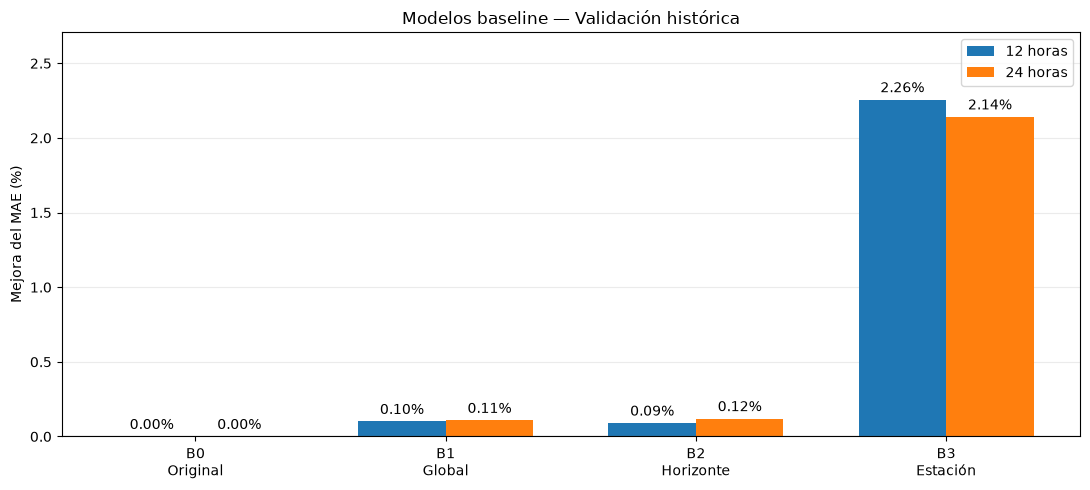

RESULTADO GLOBAL DEFINITIVO:


,horizonte_h,modelo,registros,MAE_c,RMSE_c,sesgo_c,mejora_MAE_pct
3,Global,B3 - Sesgo por estación,173583,1.5297,1.9218,0.1544,2.1985
2,Global,B2 - Sesgo por horizonte,173583,1.5625,1.9698,0.1277,0.1046
1,Global,B1 - Sesgo global,173583,1.5625,1.9698,0.1277,0.1042
0,Global,B0 - Original,173583,1.5641,1.9719,0.1570,0.0000



ARCHIVOS GENERADOS:
01_baselines_por_horizonte.csv - 893 bytes
02_baselines_globales.csv - 501 bytes
03_sesgos_por_estacion.csv - 36466 bytes
04_comparacion_baselines.png - 56660 bytes

CONTROL FINAL:
Cuatro baselines evaluados.
Mejor baseline: B3 - Sesgo por estación
Mejora MAE: 2.1985%
Evaluación histórica sin utilizar noviembre.
Notebook 05 listo para cierre.


In [6]:

# ==========================================
# 05 - CELDA 5
# CIERRE Y EXPORTACIÓN DE BASELINES
# ==========================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------
# 1. CARPETA DE RESULTADOS
# ------------------------------------------

carpeta_baselines = (
    Path(raiz_proyecto) / "resultados_baselines"
)

carpeta_baselines.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------
# 2. EXPORTAR MÉTRICAS
# ------------------------------------------

df_baselines_03.to_csv(
    carpeta_baselines / "01_baselines_por_horizonte.csv",
    index=False,
    encoding="utf-8-sig"
)

df_baselines_global_03.to_csv(
    carpeta_baselines / "02_baselines_globales.csv",
    index=False,
    encoding="utf-8-sig"
)

estadisticas_estaciones.reset_index().to_csv(
    carpeta_baselines / "03_sesgos_por_estacion.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------
# 3. GRÁFICO DE MEJORA POR HORIZONTE
# ------------------------------------------

orden_modelos = [
    "B0 - Original",
    "B1 - Sesgo global",
    "B2 - Sesgo por horizonte",
    "B3 - Sesgo por estación"
]

tabla_grafico = (
    df_baselines_03
    .pivot(
        index="modelo",
        columns="horizonte_h",
        values="mejora_MAE_pct"
    )
    .reindex(orden_modelos)
)

assert not tabla_grafico.isna().any().any()

x = np.arange(len(orden_modelos))
ancho = 0.35

fig, ax = plt.subplots(figsize=(11, 5))

for desplazamiento, horizonte in [
    (-ancho / 2, 12),
    (ancho / 2, 24)
]:
    barras = ax.bar(
        x + desplazamiento,
        tabla_grafico[horizonte],
        width=ancho,
        label=f"{horizonte} horas"
    )

    ax.bar_label(
        barras,
        fmt="%.2f%%",
        padding=3
    )

ax.set_xticks(x)
ax.set_xticklabels(
    [
        "B0\nOriginal",
        "B1\nGlobal",
        "B2\nHorizonte",
        "B3\nEstación"
    ]
)

ax.set_ylabel("Mejora del MAE (%)")
ax.set_title(
    "Modelos baseline — Validación histórica"
)

ax.axhline(0, color="gray", linewidth=0.8)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend()

ax.set_ylim(
    0,
    max(2.6, tabla_grafico.max().max() * 1.2)
)

fig.tight_layout()

fig.savefig(
    carpeta_baselines / "04_comparacion_baselines.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------
# 4. VERIFICAR RESULTADOS
# ------------------------------------------

print("RESULTADO GLOBAL DEFINITIVO:")

display(
    df_baselines_global_03.sort_values(
        "MAE_c"
    ).round(4)
)

print("\nARCHIVOS GENERADOS:")

for archivo in sorted(carpeta_baselines.iterdir()):
    if archivo.is_file():
        print(
            archivo.name,
            "-",
            archivo.stat().st_size,
            "bytes"
        )

# ------------------------------------------
# 5. AUDITORÍA DE CIERRE
# ------------------------------------------

assert len(df_baselines_03) == 8
assert len(df_baselines_global_03) == 4

mejor_baseline = (
    df_baselines_global_03
    .sort_values("MAE_c")
    .iloc[0]
)

assert (
    mejor_baseline["modelo"]
    == "B3 - Sesgo por estación"
)

print("\nCONTROL FINAL:")
print("Cuatro baselines evaluados.")
print("Mejor baseline:", mejor_baseline["modelo"])
print(
    "Mejora MAE:",
    f"{mejor_baseline['mejora_MAE_pct']:.4f}%"
)
print("Evaluación histórica sin utilizar noviembre.")
print("Notebook 05 listo para cierre.")


La comparación muestra claramente que la corrección por estación (B3) supera a las correcciones globales y por horizonte.

| Baseline |	Mejora MAE · 12 h |	Mejora MAE · 24 h |
|----------|----------------------|-------------------|
| B0 — Original	| 0,00 % |	 0,00 % |
| B1 — Global |	0,10 % |	 0,11 % |
| B2 — Horizonte |	0,09 % |	0,12 % |
| B3 — Estación |	2,26 % |	2,14 % |

Esto nos permite cerrar la parte de análisis del Notebook 05 — Modelos Baseline. Solo queda comprobar que los archivos se hayan exportado, algo que no podemos verificar únicamente con la imagen.